In [28]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


In [29]:
# --- 1. Data Transforms ---
train_transform = transforms.Compose([
    transforms.Resize((32, 32)), # CIFAR-10 is originally 32x32. Resizing to 224 is unnecessary and slow.
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15), # Reduced rotation for small images
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.CIFAR10(root='.', train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root='.', train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

# CIFAR-10 class names for visualization
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [30]:
# --- 2. Defining a Classification Model ---
class EncoderBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, (3, 3), padding=1)
        self.r1 = nn.ReLU()
        self.c2 = nn.Conv2d(cout, cout, (3, 3), padding=1)
        self.r2 = nn.ReLU()
        self.p = nn.MaxPool2d((2, 2))

    def forward(self, x):
        x = self.c1(x)
        x = self.r1(x)
        x = self.c2(x)
        x = self.r2(x)
        x = self.p(x)
        return x

class SimpleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # Input size: 3x32x32
        self.e1 = EncoderBlock(3, 64)   # Output: 64x16x16
        self.e2 = EncoderBlock(64, 128) # Output: 128x8x8
        self.e3 = EncoderBlock(128, 256)# Output: 256x4x4
        self.e4 = EncoderBlock(256, 512)# Output: 512x2x2

        self.flatten = nn.Flatten()
        # 512 channels * 2 height * 2 width = 2048
        self.fc1 = nn.Linear(512 * 2 * 2, 512)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, 10) # 10 classes for CIFAR-10

    def forward(self, x):
        x = self.e1(x)
        x = self.e2(x)
        x = self.e3(x)
        x = self.e4(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        o = self.fc2(x)
        return o

model = SimpleClassifier().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [31]:
# --- 3. Training Loop ---
def train_epoch(dataloader, model, loss_fn, optimizer):
    model.train()
    train_loss = 0
    num_batches = len(dataloader)

    for x, y in tqdm(dataloader, leave=False):
        x, y = x.to(device), y.to(device)

        pred = model(x)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    return train_loss / num_batches

def test_epoch(dataloader, model, loss_fn):
    model.eval()
    num_batches = len(dataloader)
    test_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in tqdm(dataloader, leave=False):
            x, y = x.to(device), y.to(device)

            pred = model(x)
            test_loss += loss_fn(pred, y).item()

            _, predicted = torch.max(pred.data, 1)
            total += y.size(0)
            correct += (predicted == y).sum().item()

    accuracy = 100 * correct / total
    return test_loss / num_batches, accuracy

epochs = 10 # Reduced for quicker testing, increase for better results
for t in range(epochs):
    print(f"\nEpoch {t+1}\n-------------------------------")
    train_loss = train_epoch(train_loader, model, loss_function, optimizer)
    print(f"Train Loss: {train_loss:>7f}")

    test_loss, test_acc = test_epoch(test_loader, model, loss_function)
    print(f"Test Loss: {test_loss:>7f}, Test Accuracy: {test_acc:.2f}%")


Epoch 1
-------------------------------


Train Loss: 1.786993


Test Loss: 1.442773, Test Accuracy: 46.36%

Epoch 2
-------------------------------


Train Loss: 1.369721


Test Loss: 1.181394, Test Accuracy: 57.08%

Epoch 3
-------------------------------


...

Test Loss: 0.693478, Test Accuracy: 76.86%

Epoch 9
-------------------------------


Train Loss: 0.706790


Test Loss: 0.665621, Test Accuracy: 77.26%

Epoch 10
-------------------------------


Train Loss: 0.690906


Test Loss: 0.704568, Test Accuracy: 76.48%


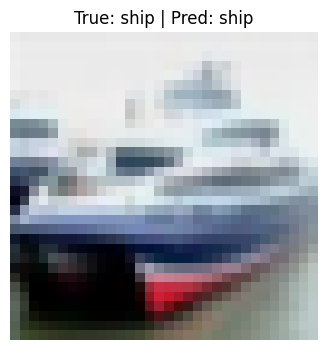

In [ ]:
# --- 4. Visualization ---
def denormalize(tensor):
    """Denormalizes a tensor to [0, 1] range for visualization."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # Clone the tensor so we don't modify the original
    tensor = tensor.clone().detach().cpu()

    # Reverse the normalization: image = (image * std) + mean
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)

    # Clamp to ensure values are between 0 and 1
    tensor = torch.clamp(tensor, 0, 1)
    return tensor

model.eval()
# Get a single image and label
img, label = test_dataset[1]

# Make prediction
with torch.no_grad():
    output = model(img.unsqueeze(0).to(device))
    _, predicted_idx = torch.max(output, 1)
    predicted_class = classes[predicted_idx.item()]
    true_class = classes[label]

# Denormalize the image for display
img_display = denormalize(img)

# Plotting
plt.figure(figsize=(4, 4))
plt.imshow(img_display.permute(1, 2, 0)) # Permute to HxWxC
plt.title(f"True: {true_class} | Pred: {predicted_class}")
plt.axis('off')
plt.show()